# A per-sample N_φ rule for the numerical (m,n)-mode projection

At each time sample the numerical route chooses the number of azimuths from the separation parameter C1 of the field point and the particle, N_φ = the smallest power of two that is at least max(64, c/√C1) (form A) or max(64, 20 + c/√C1) (form B), with the azimuth grid aligned with the particle. This notebook selects the constant c and a single number of time samples N_t for which the (m,n)-modes with 0 ≤ m ≤ 20 and |n| ≤ 20 reach E ≤ 10⁻⁸ at every test point and on every shifted time grid, and compares the cost in pointwise evaluations with fixed azimuth grids. inspectre is the reference implementation, and the results are requirements for an implementation of the source generation in spectre. The data come from `test/nphi_rule.py`; the design is `notes/inspectre/2026-10-12-nphi-rule-design.md`.

In [1]:
import json
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import NullFormatter

DATA = os.path.join("..", "data")
points = pd.read_csv(os.path.join(DATA, "nphi_rule_points.csv"))
rows = pd.read_csv(os.path.join(DATA, "nphi_rule.csv.gz"))
summary = pd.read_csv(os.path.join(DATA, "nphi_rule_summary.csv"))
selection = pd.read_csv(os.path.join(DATA, "nphi_rule_selection.csv"))
cost = pd.read_csv(os.path.join(DATA, "nphi_rule_cost.csv"))
mapsum = pd.read_csv(os.path.join(DATA, "nphi_nt_map_summary.csv"))
with open(os.path.join(DATA, "nphi_rule.meta.json")) as f:
    meta = json.load(f)

INK = "#52514e"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "lines.linewidth": 1.5, "lines.markersize": 4, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})
R_MIN, R_MAX = 100 / 13, 100 / 7
TARGET = meta["target"]
CS = meta["cs"]
NTS = meta["n_ts"]
FORMS = meta["forms"]
FORM_COLOR = {"A": SERIES[0], "B": SERIES[1]}
SET_COLOR = {"jittered": SERIES[0], "innermost": SERIES[1], "spectre": SERIES[2]}
emax = rows.groupby(["label", "form", "N_t", "c"]).E.agg(["min", "max"]).reset_index()

## Run metadata

In [2]:
u = meta["unit_costs"]
print("orbit (a, p, e):", meta["orbit"], " target", TARGET, " reference test", meta["ref_tol"])
print("forms", FORMS, " c", CS, " N_t", NTS, " samples per pass", meta["n_samples"], "up to", meta["n_samples_max"])
print(f"unit costs: {u['t_eval'] * 1e6:.3f} µs per evaluation, {u['t_call'] * 1e3:.3f} ms per call at N_phi = 64, "
      f"{u['t_max']:.2f} s at N_phi = 2^22")
print(f"{meta['points']} points, {meta['worldtube_points']} worldtube Gauss points for the cost, "
      f"wall time {meta['wall_seconds'] / 3600:.2f} h")
one = summary.drop_duplicates("label")
print(one.groupby(["set", "verified"]).size().rename("points").to_string())
print("largest noise level per set:", one.groupby("set").noise.max().map(lambda v: f"{v:.1e}").to_dict())
print("N_ref counts:", one.N_ref.value_counts().to_dict())
one[~one.verified][["label", "N_ref", "noise"]]

orbit (a, p, e): [0.5, 10.0, 0.3]  target 1e-08  reference test 1e-09
forms ['A', 'B']  c [8, 10, 12, 14, 16, 20, 24, 28, 37]  N_t [1024, 2048, 4096, 8192]  samples per pass 32768 up to 131072
unit costs: 0.474 µs per evaluation, 0.477 ms per call at N_phi = 64, 1.99 s at N_phi = 2^22
667 points, 9218 worldtube Gauss points for the cost, wall time 2.43 h
set        verified
innermost  False         1
           True          8
jittered   True        126
map        True        232
spectre    True        300
largest noise level per set: {'innermost': '6.2e-10', 'jittered': '2.9e-10', 'map': '2.6e-10', 'spectre': '8.7e-11'}
N_ref counts: {32768: 664, 65536: 2, 131072: 1}


,label,N_ref,noise
2864,"inner:r=39/5,dth=3.3902267683727596e-05",131072,5.953191e-11


## Selection

For each verdict (all four sets, or the sets down to the seventh refinement of the spectre grid), form and N_t: the selected c is the largest c_min over the verified points, empty when some point fails at c = 37. The total cost is the number of pointwise evaluations of one single-m run, summed over the worldtube Gauss points on the unshifted grid, against a fixed grid of 65536 azimuths at every point. The selected pair has the smallest total cost.

In [3]:
sel = selection.drop_duplicates(["verdict", "form", "N_t"])[["verdict", "form", "N_t", "selected_c"]].copy()
def total_at(r):
    if pd.isna(r.selected_c):
        return np.nan
    return cost[(cost.form == r.form) & (cost.N_t == r.N_t) & (cost.c == r.selected_c)].total_evals.iloc[0]
sel["total_evals"] = sel.apply(total_at, axis=1)
sel["fixed_65536"] = sel.N_t * 65536.0 * meta["worldtube_points"]
sel["ratio"] = sel.total_evals / sel.fixed_65536
sel["selected"] = [meta["selected"][v][f] == [n, c] if meta["selected"][v][f] and pd.notna(c) else False
                   for v, f, n, c in zip(sel.verdict, sel.form, sel.N_t, sel.selected_c)]
print("selected pairs (N_t, c):", meta["selected"])
pd.set_option("display.float_format", lambda v: f"{v:.3g}")
sel

selected pairs (N_t, c): {'all': {'A': [4096, 24], 'B': [4096, 16]}, 'to7': {'A': [2048, 24], 'B': [2048, 16]}}


,verdict,form,N_t,selected_c,total_evals,fixed_65536,ratio,selected
0,all,A,1024,NaN,NaN,6.19e+11,NaN,False
9,all,A,2048,NaN,NaN,1.24e+12,NaN,False
18,all,A,4096,24,2.62e+10,2.47e+12,0.0106,True
27,all,A,8192,24,5.24e+10,4.95e+12,0.0106,False
36,all,B,1024,NaN,NaN,6.19e+11,NaN,False
45,all,B,2048,NaN,NaN,1.24e+12,NaN,False
54,all,B,4096,16,1.85e+10,2.47e+12,0.00749,True
63,all,B,8192,16,3.71e+10,4.95e+12,0.00749,False
72,to7,A,1024,NaN,NaN,6.19e+11,NaN,False
81,to7,A,2048,24,1.31e+10,1.24e+12,0.0106,True


In [4]:
fails = selection[selection.verdict == "all"].pivot_table(index=["form", "c"], columns="N_t", values="fail_total")
fails

N_t      1024  2048  4096  8192
form c                         
A    8    634   634   634   634
     10   634   634   634   634
     12   624   624   624   624
     14   598   580   575   573
     16   339   323   322   322
     20    67    52    50    48
     24    20     3     0     0
     28    21     2     0     0
     37    21     1     0     0
B    8    634   634   634   634
     10   615   615   615   615
     12   487   457   444   441
     14    54    37    34    33
     16    19     3     0     0
     20    19     3     0     0
     24    20     3     0     0
     28    21     2     0     0
     37    21     1     0     0

## c_min over the interior of the map

Each cell shows c_min, the smallest scanned c for which the point passes at that c and every larger one; `>` marks a point that fails at c = 37 and `*` an unverified reference. The radial range of the orbit lies between the dashed lines.

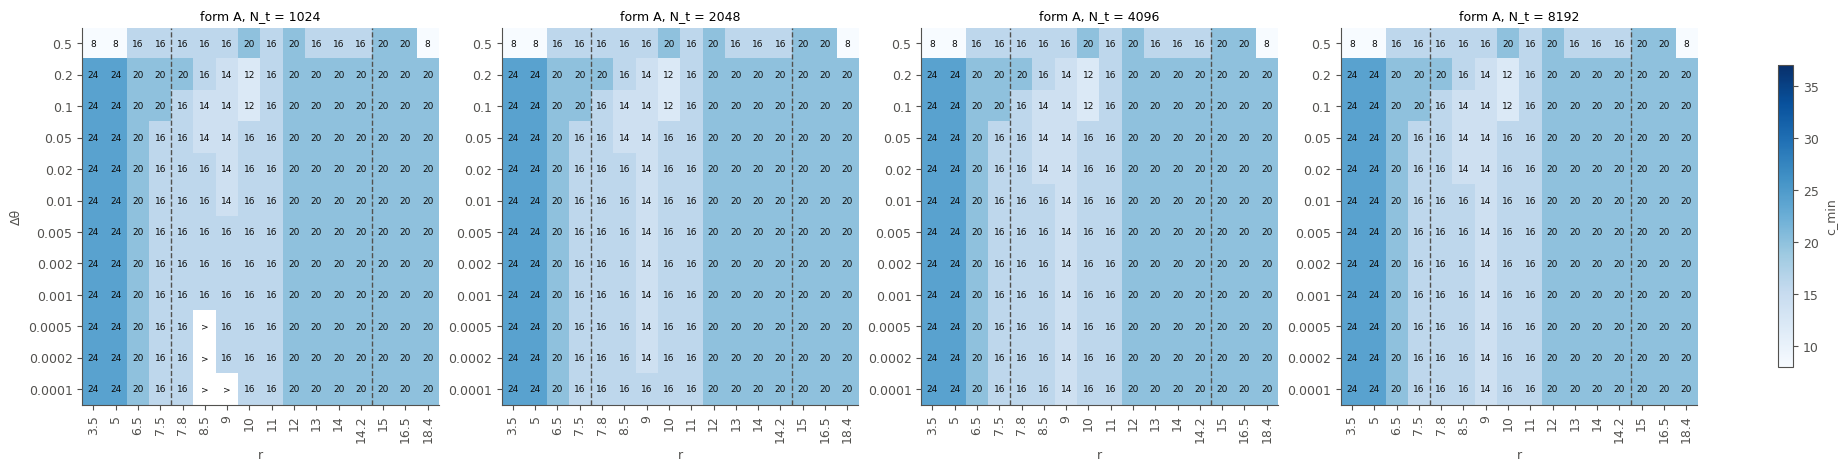

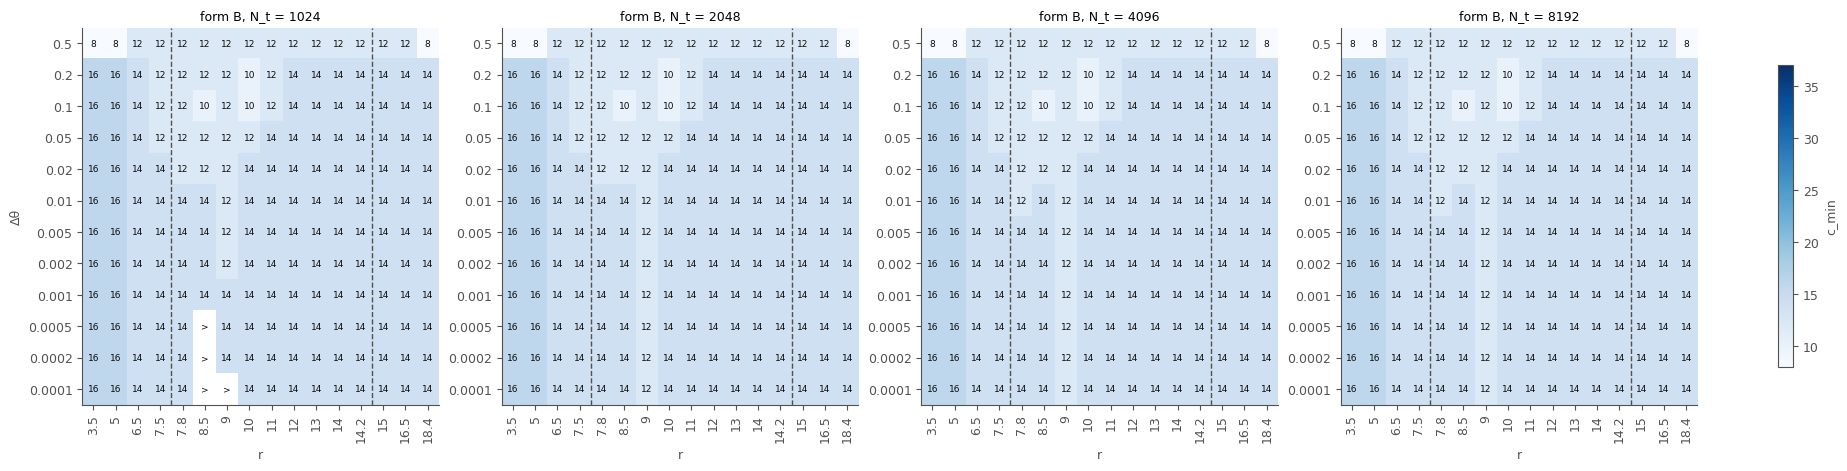

In [5]:
inner = summary.merge(points[["label", "set"]], on=["label", "set"])
inner = inner[(inner.set == "map") & (inner.kind == "interior")]
rs = sorted(inner.r.unique())
ds = sorted(inner.dth.unique(), reverse=True)
for form in FORMS:
    fig, axes = plt.subplots(1, len(NTS), figsize=(4.6 * len(NTS), 4.6), constrained_layout=True, squeeze=False)
    for ax, n_t in zip(axes[0], NTS):
        g = inner[(inner.form == form) & (inner.N_t == n_t)]
        grid = np.full((len(ds), len(rs)), np.nan)
        for _, s in g.iterrows():
            i, j = ds.index(s.dth), rs.index(s.r)
            if pd.notna(s.c_min):
                grid[i, j] = s.c_min
            text = f"{int(s.c_min)}" if pd.notna(s.c_min) else ">"
            ax.text(j, i, text + ("" if s.verified else "*"), ha="center", va="center", fontsize=6.5, color="#0b0b0b")
        im = ax.imshow(grid, cmap="Blues", aspect="auto", vmin=min(CS), vmax=max(CS))
        ax.set_xticks(range(len(rs)), [f"{r:g}" for r in rs], rotation=90)
        ax.set_yticks(range(len(ds)), [f"{d:g}" for d in ds])
        ax.grid(False)
        for x in (sum(r < R_MIN for r in rs) - 0.5, sum(r < R_MAX for r in rs) - 0.5):
            ax.axvline(x, color=INK, linestyle="--", linewidth=1)
        ax.set_title(f"form {form}, N_t = {n_t}", fontsize=9)
        ax.set_xlabel("r")
    axes[0, 0].set_ylabel("Δθ")
    fig.colorbar(im, ax=axes[0], label="c_min", shrink=0.8)
    plt.show()

## E against c at representative points

The line is the largest E over the shifted time grids and the band spans the smallest to the largest. The dashed line is the target 10⁻⁸.

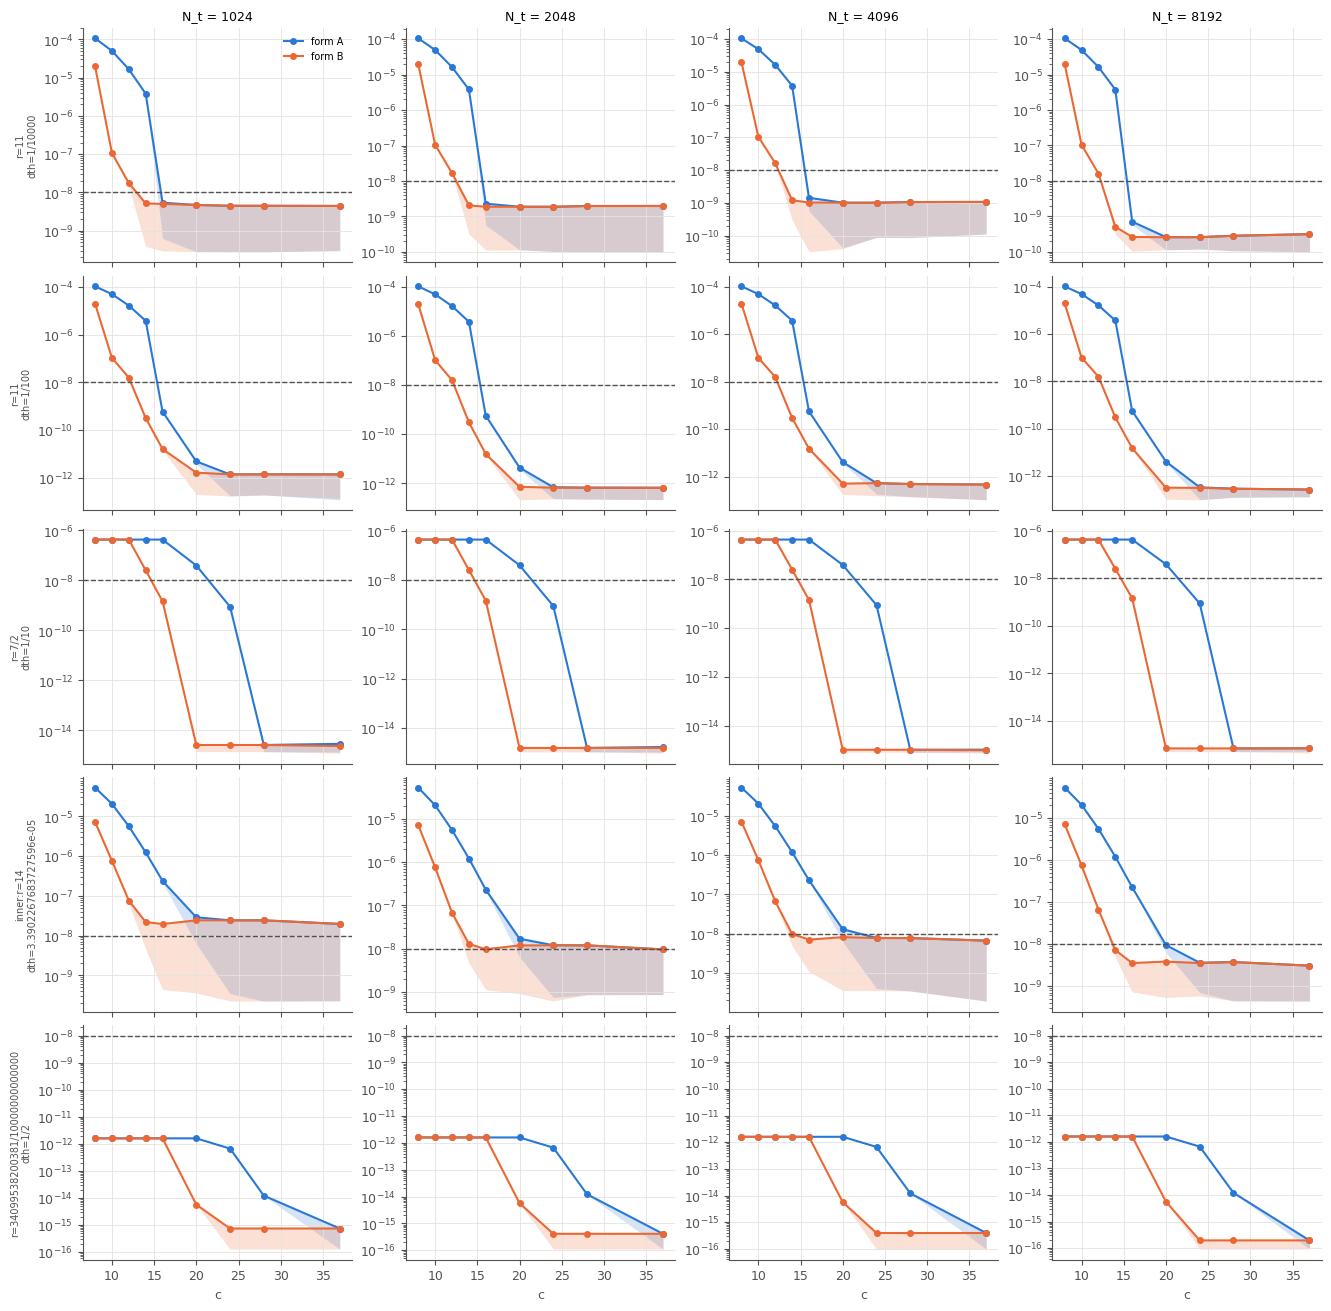

In [6]:
labels = points.set_index("label")
picks = ["r=11,dth=1/10000", "r=11,dth=1/100", "r=7/2,dth=1/10"]
picks += [l for l in points[points.set == "innermost"].label if l.startswith("inner:r=14,")][:1]
picks += [l for l in points[points.set == "map"].label if l.startswith("r=34099538200381")][:1]
picks = [p for p in picks if p in set(emax.label)]
fig, axes = plt.subplots(len(picks), len(NTS), figsize=(3.3 * len(NTS), 2.6 * len(picks)), constrained_layout=True,
                         squeeze=False, sharex=True)
for i, lab in enumerate(picks):
    for j, n_t in enumerate(NTS):
        ax = axes[i, j]
        for form in FORMS:
            g = emax[(emax.label == lab) & (emax.form == form) & (emax.N_t == n_t)].sort_values("c")
            ax.fill_between(g.c, g["min"].clip(lower=1e-17), g["max"].clip(lower=1e-17), color=FORM_COLOR[form],
                            alpha=0.2, linewidth=0)
            ax.semilogy(g.c, g["max"].clip(lower=1e-17), "-o", color=FORM_COLOR[form], label=f"form {form}")
        ax.axhline(TARGET, color=INK, linestyle="--", linewidth=1)
        if i == 0:
            ax.set_title(f"N_t = {n_t}", fontsize=9)
        if j == 0:
            ax.set_ylabel(lab.replace(",", "\n"), fontsize=7)
        if i == len(picks) - 1:
            ax.set_xlabel("c")
axes[0, 0].legend(frameon=False, fontsize=7)
plt.show()

## Robustness off the grid of the map

c_min at the jittered points, the innermost row and the spectre Gauss points, at each N_t; a point that fails at c = 37 is drawn at the top edge as a triangle. The lower row shows the fraction of time samples at the floor of 64 azimuths at c_min.

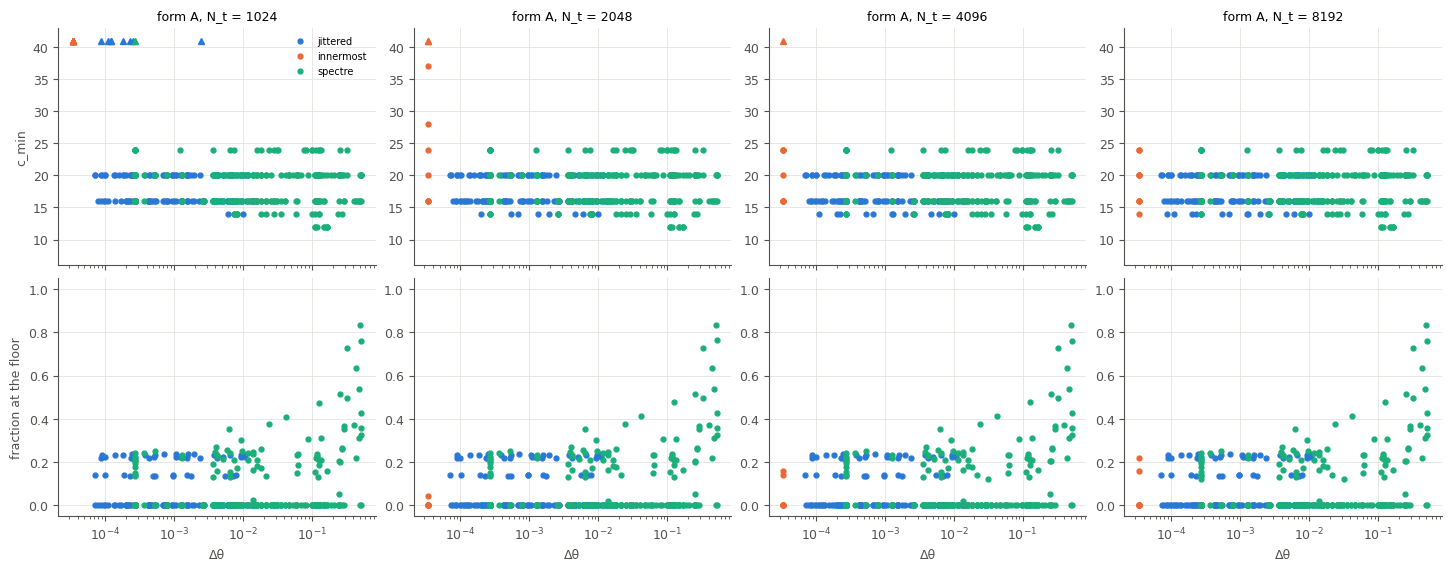

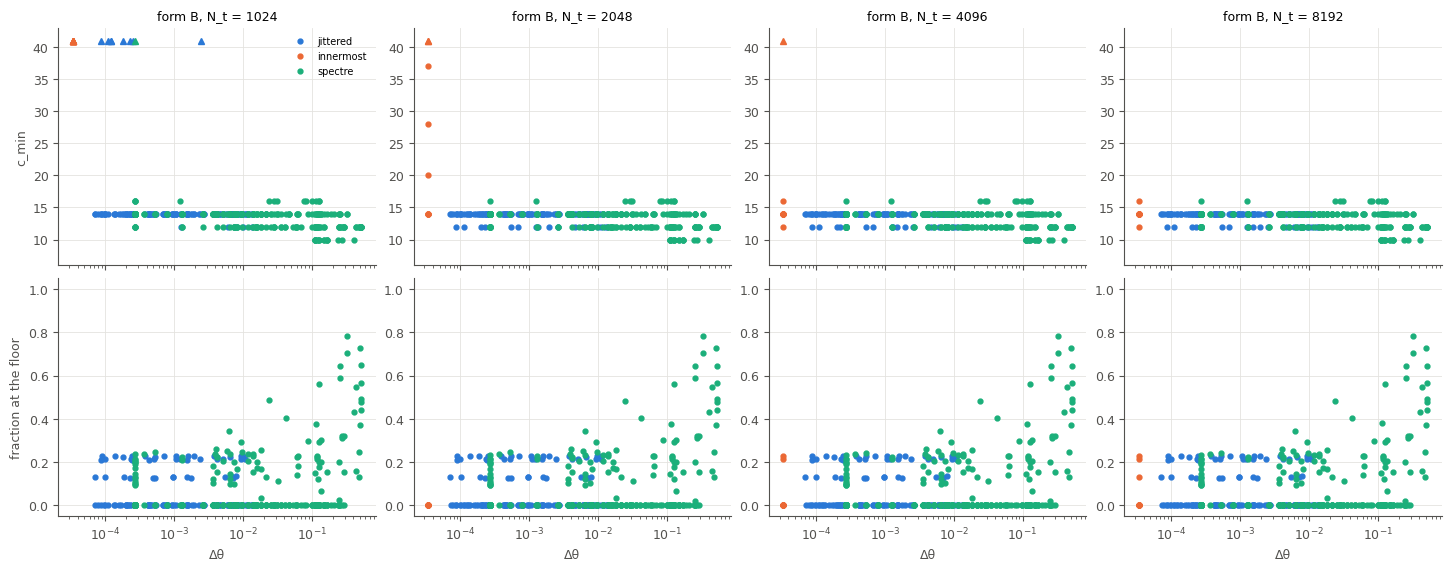

In [7]:
extra = summary[summary.set.isin(list(SET_COLOR))]
for form in FORMS:
    fig, axes = plt.subplots(2, len(NTS), figsize=(3.6 * len(NTS), 5.6), constrained_layout=True, squeeze=False,
                             sharex=True)
    for j, n_t in enumerate(NTS):
        g = extra[(extra.form == form) & (extra.N_t == n_t)]
        for st, col in SET_COLOR.items():
            h = g[g.set == st]
            ok = h[h.c_min.notna()]
            axes[0, j].semilogx(ok.dth, ok.c_min, "o", color=col, label=st, markersize=3.5)
            bad = h[h.c_min.isna()]
            axes[0, j].semilogx(bad.dth, np.full(len(bad), max(CS) + 4), "^", color=col, markersize=5)
            axes[1, j].semilogx(ok.dth, ok.frac_floor, "o", color=col, markersize=3.5)
        axes[0, j].set_ylim(min(CS) - 2, max(CS) + 6)
        axes[0, j].set_title(f"form {form}, N_t = {n_t}", fontsize=9)
        axes[1, j].set_xlabel("Δθ")
        axes[1, j].set_ylim(-0.05, 1.05)
    axes[0, 0].set_ylabel("c_min")
    axes[1, 0].set_ylabel("fraction at the floor")
    axes[0, 0].legend(frameon=False, fontsize=7)
    plt.show()

## Cost

Left: the evaluations of one single-m run at each point of the map's interior on the unshifted grid, for the selected rule of each form (verdict over all sets), against the fixed grid N_t × N_φ_all of the map. Right: the total over the worldtube Gauss points against c, for each N_t, against a fixed grid of 65536 azimuths.

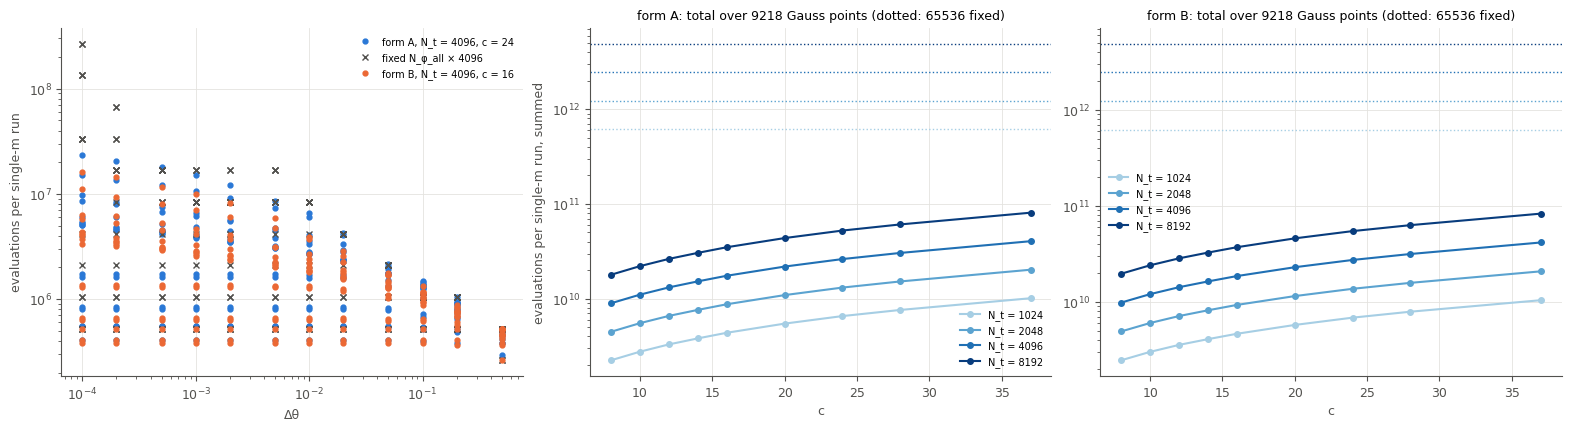

In [8]:
fig, axes = plt.subplots(1, 1 + len(FORMS), figsize=(5.2 * (1 + len(FORMS)), 4.2), constrained_layout=True)
nphi_all = mapsum.set_index("label").Nphi_all
ax = axes[0]
fixed_nts = set()
for k, form in enumerate(FORMS):
    pair = meta["selected"]["all"][form] or meta["selected"]["to7"][form]
    if not pair:
        continue
    n_t, c = pair
    g = rows[(rows.set == "map") & (rows.kind == "interior") & (rows.form == form) & (rows.N_t == n_t)
             & (rows.c == c) & (rows["shift"] == 0)].merge(points[["label", "dth"]], on="label")
    ax.loglog(g.dth, g.evals, "o", color=FORM_COLOR[form], markersize=3.5, label=f"form {form}, N_t = {n_t}, c = {c}")
    if n_t not in fixed_nts:
        fixed_nts.add(n_t)
        ax.loglog(g.dth, g.label.map(nphi_all) * n_t, "x", color=INK, markersize=4, label=f"fixed N_φ_all × {n_t}")
ax.set_xlabel("Δθ")
ax.set_ylabel("evaluations per single-m run")
ax.legend(frameon=False, fontsize=7)
for ax, form in zip(axes[1:], FORMS):
    for k, n_t in enumerate(NTS):
        g = cost[(cost.form == form) & (cost.N_t == n_t)].sort_values("c")
        col = plt.cm.Blues(0.35 + 0.6 * k / max(1, len(NTS) - 1))
        ax.semilogy(g.c, g.total_evals, "-o", color=col, label=f"N_t = {n_t}")
        ax.axhline(g.fixed_65536_total.iloc[0], color=col, linestyle=":", linewidth=1)
    ax.set_title(f"form {form}: total over {meta['worldtube_points']} Gauss points (dotted: 65536 fixed)", fontsize=9)
    ax.set_xlabel("c")
    ax.legend(frameon=False, fontsize=7)
axes[1].set_ylabel("evaluations per single-m run, summed")
plt.show()

## Time and azimuthal parts at the selected pairs

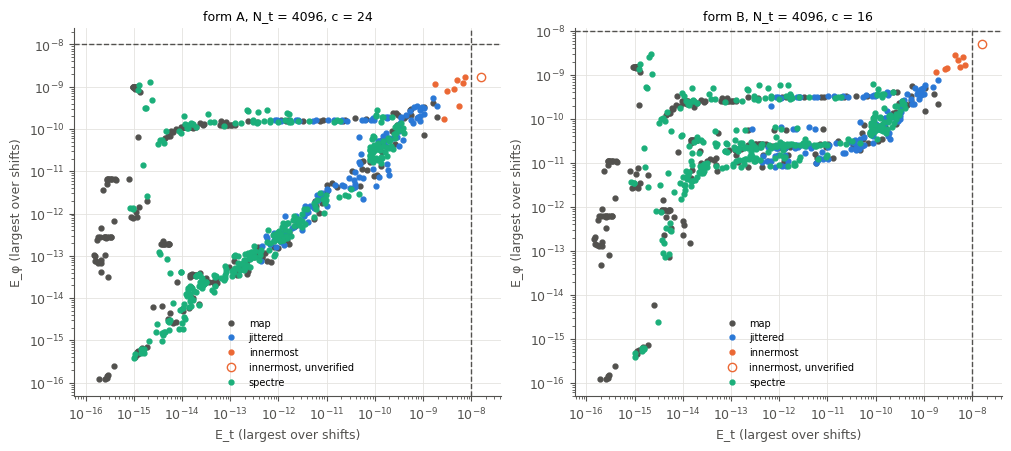

In [9]:
fig, axes = plt.subplots(1, len(FORMS), figsize=(5.0 * len(FORMS), 4.4), constrained_layout=True, squeeze=False)
for ax, form in zip(axes[0], FORMS):
    pair = meta["selected"]["all"][form] or meta["selected"]["to7"][form]
    if not pair:
        ax.set_title(f"form {form}: no selected pair", fontsize=9)
        continue
    n_t, c = pair
    g = rows[(rows.form == form) & (rows.N_t == n_t) & (rows.c == c)].groupby(["label", "set"])[["E_t", "E_phi"]].max()
    g = g.reset_index()
    g["verified"] = g.label.map(summary.drop_duplicates("label").set_index("label").verified)
    for st, col in {"map": INK, **SET_COLOR}.items():
        h = g[(g.set == st) & g.verified]
        ax.loglog(h.E_t.clip(lower=1e-17), h.E_phi.clip(lower=1e-17), "o", markersize=3.5, color=col, label=st)
        h = g[(g.set == st) & ~g.verified]
        if len(h):
            ax.loglog(h.E_t.clip(lower=1e-17), h.E_phi.clip(lower=1e-17), "o", markersize=6, markerfacecolor="none",
                      markeredgecolor=col, label=f"{st}, unverified")
    ax.axhline(TARGET, color=INK, linestyle="--", linewidth=1)
    ax.axvline(TARGET, color=INK, linestyle="--", linewidth=1)
    ax.set_xlabel("E_t (largest over shifts)")
    ax.set_ylabel("E_φ (largest over shifts)")
    ax.set_title(f"form {form}, N_t = {n_t}, c = {c}", fontsize=9)
    ax.legend(frameon=False, fontsize=7)
plt.show()

## Margins at the binding points

For each form, at its selected pair over all sets (or down to the seventh refinement when none exists over all sets), the twelve verified points with the largest E: the largest and smallest E over the shifted time grids, the noise of the reference on that time grid (the largest change over the shifts when λ moves by one unit in the last place at the samples with N_φ ≥ 2^14), and the reference test e_half.

In [10]:
one = summary.drop_duplicates("label").set_index("label")
tabs = []
for form in FORMS:
    pair = meta["selected"]["all"][form] or meta["selected"]["to7"][form]
    if not pair:
        continue
    n_t, c = pair
    g = emax[(emax.form == form) & (emax.N_t == n_t) & (emax.c == c)].copy()
    g = g[g.label.map(one.verified)]
    g["ratio"] = g["max"] / g["min"]
    nt = summary[(summary.form == form) & (summary.N_t == n_t)].set_index("label")
    g["noise_t"] = g.label.map(nt.noise_t)
    g["e_half"] = g.label.map(one.e_half)
    g["N_ref"] = g.label.map(one.N_ref)
    g.insert(0, "pair", f"{form}: N_t = {n_t}, c = {c}")
    tabs.append(g.sort_values("max", ascending=False).head(12))
pd.concat(tabs)[["pair", "label", "max", "min", "ratio", "noise_t", "e_half", "N_ref"]] if tabs else "no selected pair"

,pair,label,max,min,ratio,noise_t,e_half,N_ref
312,"A: N_t = 4096, c = 24","inner:r=14,dth=3.3902267683727596e-05",7.72e-09,3.96e-10,19.5,2.78e-09,8.36e-10,65536
384,"A: N_t = 4096, c = 24","inner:r=17/2,dth=3.3902267683727596e-05",7.63e-09,2.57e-10,29.7,2.9e-09,8.03e-10,65536
528,"A: N_t = 4096, c = 24","inner:r=71/5,dth=3.3902267683727596e-05",5.59e-09,1.18e-09,4.74,2.3e-09,6.86e-10,32768
168,"A: N_t = 4096, c = 24","inner:r=12,dth=3.3902267683727596e-05",5.56e-09,5.71e-10,9.73,3.67e-09,3.63e-10,32768
240,"A: N_t = 4096, c = 24","inner:r=13,dth=3.3902267683727596e-05",4.75e-09,2.95e-10,16.1,1.25e-09,3.97e-10,32768
24,"A: N_t = 4096, c = 24","inner:r=10,dth=3.3902267683727596e-05",3.09e-09,3.67e-10,8.42,1.43e-09,3.78e-10,32768
96,"A: N_t = 4096, c = 24","inner:r=11,dth=3.3902267683727596e-05",2.69e-09,1.99e-10,13.5,3.16e-09,3.51e-10,32768
6864,"A: N_t = 4096, c = 24","jit:r=7.8242076648839847,dth=8.596195942616355...",2.25e-09,3.81e-10,5.91,8.72e-10,2.58e-10,32768
600,"A: N_t = 4096, c = 24","inner:r=9,dth=3.3902267683727596e-05",2.05e-09,3.01e-10,6.8,5.65e-10,2.13e-10,32768
17448,"A: N_t = 4096, c = 24","r=17/2,dth=1/10000",2e-09,1.89e-10,10.6,2.98e-10,2.55e-10,32768


The time grid starts are a sample: at N_t = 4096 the main run tests 8 starts. A second run of the innermost row with 2^17 samples per pass tests 32 starts at N_t = 4096 (16 at 8192, 64 at 2048). The table compares the largest E over the starts of both runs at the selected c of each form.

In [11]:
pd.set_option("display.max_rows", 100)
fine_dir = os.path.join(DATA, "nphi_rule_innermost_fine")
if os.path.exists(os.path.join(fine_dir, "nphi_rule.csv.gz")):
    fine = pd.read_csv(os.path.join(fine_dir, "nphi_rule.csv.gz"))
    fsum = pd.read_csv(os.path.join(fine_dir, "nphi_rule_summary.csv")).drop_duplicates("label").set_index("label")
    out = []
    for form in FORMS:
        c = (meta["selected"]["all"][form] or meta["selected"]["to7"][form] or [None, None])[1]
        if c is None:
            continue
        for n_t in NTS:
            a = emax[(emax.form == form) & (emax.c == c) & (emax.N_t == n_t) & emax.label.str.startswith("inner:")]
            b = fine[(fine.form == form) & (fine.c == c) & (fine.N_t == n_t)].groupby("label").E.max()
            t = a.set_index("label")["max"].rename("E_max, base starts").to_frame()
            t["E_max, fine starts"] = b
            t["fine verified"] = fsum.verified
            t["fine noise_t"] = pd.read_csv(os.path.join(fine_dir, "nphi_rule_summary.csv")).query(
                "form == @form and N_t == @n_t").set_index("label").noise_t
            t.insert(0, "N_t", n_t)
            t.insert(0, "form, c", f"{form}, {c}")
            out.append(t.reset_index())
    display(pd.concat(out) if out else "no selected pair")
else:
    print("no fine run of the innermost row")

,label,"form, c",N_t,"E_max, base starts","E_max, fine starts",fine verified,fine noise_t
0,"inner:r=10,dth=3.3902267683727596e-05","A, 24",1024,1.39e-08,1.8e-08,True,2.53e-08
1,"inner:r=11,dth=3.3902267683727596e-05","A, 24",1024,1.21e-08,3.86e-08,True,2.25e-08
2,"inner:r=12,dth=3.3902267683727596e-05","A, 24",1024,1.98e-08,2e-08,True,1.34e-08
3,"inner:r=13,dth=3.3902267683727596e-05","A, 24",1024,1.18e-08,1.8e-08,True,1.88e-08
4,"inner:r=14,dth=3.3902267683727596e-05","A, 24",1024,2.42e-08,2.37e-08,True,1.74e-08
5,"inner:r=17/2,dth=3.3902267683727596e-05","A, 24",1024,4.25e-08,4.23e-08,True,1.89e-08
6,"inner:r=39/5,dth=3.3902267683727596e-05","A, 24",1024,2.94e-08,6.01e-08,False,2.99e-08
7,"inner:r=71/5,dth=3.3902267683727596e-05","A, 24",1024,1.64e-08,2.42e-08,True,1.32e-08
8,"inner:r=9,dth=3.3902267683727596e-05","A, 24",1024,1.4e-08,1.86e-08,True,1.72e-08
0,"inner:r=10,dth=3.3902267683727596e-05","A, 24",2048,6.68e-09,6.87e-09,True,1.27e-08


## Findings

**Run.** The 667 points ran in 2.43 h on 12 workers. Every reference passed its test at 2^15 samples except three points of the innermost row: (8.5, 3.39 × 10⁻⁵) and (14, 3.39 × 10⁻⁵) passed at 2^16, and (7.8, 3.39 × 10⁻⁵) failed at every N_s up to 2^17 and is excluded from the selection. No sample of any rule reached the cap of 2^22. The microbenchmark gives 0.474 µs per pointwise evaluation and 0.536 ms per call at N_φ = 64, which includes the placement, 64 evaluations and the FFT and is therefore an upper bound on a placement. A second run of the innermost row with 2^17 samples per pass tests 32 starts of the time grid at N_t = 4096 instead of 8, and there every reference passed its test except again at r = 7.8 (e_half = 3.1 × 10⁻⁹).

**Selected rules.** The totals are the evaluations of one single-m run summed over the 9218 worldtube Gauss points of the seventh refinement on the unshifted grid; the deeper refinements are not included.

| verdict | form | N_t | c | largest E (point) | evaluations per run, mean / largest | total | fixed 65536 |
|---|---|---|---|---|---|---|---|
| all sets | A | 4096 | 24 | 7.7 × 10⁻⁹ (14, 3.39 × 10⁻⁵) | 2.84 × 10⁶ / 3.59 × 10⁷ | 2.62 × 10¹⁰ | 2.47 × 10¹² |
| all sets | B | 4096 | 16 | 7.0 × 10⁻⁹ (14, 3.39 × 10⁻⁵) | 2.01 × 10⁶ / 2.25 × 10⁷ | 1.85 × 10¹⁰ | 2.47 × 10¹² |
| to the seventh refinement | A | 2048 | 24 | 3.9 × 10⁻⁹ (8.5, 10⁻⁴) | 1.42 × 10⁶ / 1.80 × 10⁷ | 1.31 × 10¹⁰ | 1.24 × 10¹² |
| to the seventh refinement | B | 2048 | 16 | 4.2 × 10⁻⁹ (8.5, 10⁻⁴) | 1.01 × 10⁶ / 1.12 × 10⁷ | 9.27 × 10⁹ | 1.24 × 10¹² |

The per-sample rules cost 1.1 % (form A) and 0.75 % (form B) of a fixed grid of 65536 azimuths at every point. At the 192 interior points of the map they cost 27 % (form A) and 19 % (form B) of the fixed grids N_t × N_φ_all of the map, 5.5 × 10⁸ and 3.9 × 10⁸ against 2.0 × 10⁹ evaluations at N_t = 4096. Form B needs 0.71 times the evaluations of form A.

**Margins.** The noise of a reference on a time grid is the largest change of its modes over the starts of that grid when λ moves by one unit in the last place at the samples with N_φ ≥ 2^14. It is rounding of the pointwise evaluator near closest approach, so any implementation of the per-sample projection in double precision meets it.

- Down to the seventh refinement, at N_t = 2048, the largest E is 3.9 × 10⁻⁹ (form A) and 4.2 × 10⁻⁹ (form B), at (8.5, 10⁻⁴), where the noise is 4.8 × 10⁻¹⁰, and the noise of the points outside the innermost row is at most 2.1 × 10⁻⁹. The margin below the target is about three times the noise.
- At the innermost row the noise is 4.2 × 10⁻⁹ to 6.3 × 10⁻⁹ on the grid of N_t = 4096 and 2.2 × 10⁻⁹ to 3.2 × 10⁻⁹ on the grid of N_t = 8192, over the 32 and 16 starts of the second run. On the 8 starts of the main run the selected pairs reach 7.7 × 10⁻⁹ (form A) and 7.0 × 10⁻⁹ (form B), and E varies by factors up to 30 between the starts. On the 32 starts of the second run, the largest E at N_t = 4096 over the verified radii is 8.2 × 10⁻⁹ for form A with c = 24 and for form B with c = 20, and 1.04 × 10⁻⁸ for form B with c = 16, at (11, 3.39 × 10⁻⁵). At N_t = 8192 it is at most 5.5 × 10⁻⁹ for both forms at their selected c. The innermost row at N_t = 4096 therefore meets the target only within the noise, and at N_t = 8192 with a margin of about 1.5 times the noise.
- At (7.8, 3.39 × 10⁻⁵), whose reference did not pass its test at 2^17 samples, the largest E over the shifts of the reference rule is 1.6 × 10⁻⁸ at N_t = 4096 and 9.7 × 10⁻⁹ at N_t = 8192, and for form B with c = 16 it is 1.0 × 10⁻⁸ at N_t = 8192.

**What sets c.** At N_t = 4096, c_min of form A over the interior of the map is 8 or 24 at r ≤ 5, 12 to 20 inside the radial range and 8 or 20 at r ≥ 15, and 8 to 16 on the faces. For form B the ranges are 8 or 16, 10 to 14, and 8 to 14, and 8 to 12 on the faces. At (3.5, 0.1), where for small c most samples sit at the floor of 64 azimuths and the mode m = 20 limits the error, form A gives E = 4.3 × 10⁻⁷ for c ≤ 16, 4.0 × 10⁻⁸ at c = 20 and 8.9 × 10⁻¹⁰ at c = 24, while form B gives 2.6 × 10⁻⁸ at c = 14 and 1.5 × 10⁻⁹ at c = 16. The floor is not the only limit: for form A, c = 24 is also required at 14 spectre points inside the radial range, at r = 12.3 to 12.9 and Δθ from 2.7 × 10⁻⁴ to 0.14, none of whose samples at c = 24 sit at the floor, and at three points of the innermost row. No point of the set jittered needs more than c = 20 (form A) or 14 (form B).

**What sets N_t.** Over all sets, N_t = 2048 fails at points of the innermost row for every c of form A from 24 to 37 (three at c = 24, one at c = 37), with E up to 1.7 × 10⁻⁸ at (8.5, 3.39 × 10⁻⁵), where the time part alone is 1.6 × 10⁻⁸. Down to the seventh refinement, N_t = 2048 passes, while N_t = 1024 fails at 12 points of the sets map, jittered and spectre for form A with c = 24 and for form B with c = 16, with E up to 1.26 × 10⁻⁸ at a jittered point near (8.5, 1.2 × 10⁻⁴); the failing points of the map are (8.5, 10⁻⁴), (8.5, 5 × 10⁻⁴) and (9, 10⁻⁴), with E = 1.05 × 10⁻⁸ to 1.10 × 10⁻⁸ for form A with c = 24. At the selected pairs over all sets the largest time part over the verified points is 7.3 × 10⁻⁹ and the largest azimuthal part 1.7 × 10⁻⁹ (form A) and 3.0 × 10⁻⁹ (form B), so the time grid takes most of the budget at the innermost row.

## Recommendations for the implementation

1. **Rule.** N_φ = the smallest power of two that is at least max(64, 20 + c/√C1) (form B). With c = 16 it meets the target at every verified point down to the seventh refinement at N_t = 2048. Form A needs c = 24 and 1.41 times the evaluations. The cap of 2^22 was not reached.
2. **Azimuth grid.** The constants hold for a grid aligned with the particle, φ_k = φ_p + 2πk/N_φ.
3. **Placement.** One placement of the particle per time sample, shared by all field points, costs at most 0.536 ms, or 1.1 s per run at N_t = 2048. The evaluations of form B with c = 16 at N_t = 2048 cost on average 1.01 × 10⁶ × 0.474 µs = 0.48 s per field point and single-m run, and at most 5.3 s.
4. **Time grid.** N_t = 2048 covers the field points down to the seventh refinement (Δθ ≥ 2.7 × 10⁻⁴) with E ≤ 4.2 × 10⁻⁹ and a noise of at most 2.1 × 10⁻⁹. The innermost refined row (Δθ = 3.39 × 10⁻⁵) needs N_t = 8192 to meet the target with a margin above the noise (E ≤ 5.5 × 10⁻⁹ at the eight verified radii, noise ≤ 3.2 × 10⁻⁹), at twice the cost of N_t = 4096 (3.71 × 10¹⁰ evaluations for form B with c = 16). At N_t = 4096 that row meets the target only within the noise, and form B there needs c = 20 on the finer set of grid starts. At r = 7.8 even N_t = 8192 gives 1.0 × 10⁻⁸ against an unverified reference.
5. **Noise.** The rounding of the pointwise evaluator near closest approach contributes up to 6.3 × 10⁻⁹ on the grid of N_t = 4096 at the innermost row and decreases roughly in proportion to 1/N_t, so a single grid that covers the innermost row at 10⁻⁸ in double precision needs N_t ≥ 8192.
6. **m_max.** Form B uses m_max = 20 for every run; a run with a single smaller m was not tested with a smaller m_max.
